# Salon Experiment & Causal Analysis
**Data Science with Python Analyst Internship - Coimbatore (YuvaIntern)**

This notebook answers one question for a fictional Coimbatore salon & spa chain: *did the change launched last quarter really improve results, and how should we test the next initiative properly?*

| Part | What it does |
|---|---|
| 0 | Load and clean the data (no-shows hidden as cancellations, messy service names, walk-ins without client ID) |
| A | Design an A/B test: hypothesis, primary and guardrail metrics, power analysis, duration |
| B | Analyse the experiment dataset: sample ratio mismatch, balance, effects with confidence intervals |
| C | Difference-in-differences for last quarter's change (no experiment), parallel-trends checks, placebo test |
| D | Segment the effect: who gained and who lost |
| E | Stretch: CUPED / regression adjustment and how much shorter the test could have been |
| F | Decision (go / no-go / extend) and what could make the estimates wrong |

**Data note.** No dataset file came with the brief, so `generate_data.py` builds a simulated dataset with the structure described (22 outlets, about 300,000 rows, the three data-quality problems). Every number below comes from that simulated data. To use the real files, put them in `data/` with the same column names and re-run this notebook.

In [1]:
import json, re, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings("ignore")

ROOT = Path(".")
DATA, FIG = ROOT / "data", ROOT / "figures"
FIG.mkdir(exist_ok=True)
rng = np.random.default_rng(42)
R = {}                                     # every key number is stored here -> results.json

BLUE, ORANGE, GREY, INK = "#2563EB", "#D9631E", "#6B7280", "#1F2937"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#9CA3AF", "axes.grid": True, "grid.color": "#E5E7EB",
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "legend.frameon": False})

def f(x): return float(x)
LAUNCH = pd.Timestamp("2026-07-01")

## 0. Load and clean the data

In [2]:
appt_raw = pd.read_csv(DATA / "appointments.csv.gz", parse_dates=["appt_date"])
prod_raw = pd.read_csv(DATA / "product_sales.csv.gz", parse_dates=["sale_date"])
outlets = pd.read_csv(DATA / "outlets.csv")
stylists = pd.read_csv(DATA / "stylists.csv")
exp = pd.read_csv(DATA / "experiment_clients.csv", parse_dates=["enrol_date", "index_appt_date"])

total_rows = len(appt_raw) + len(prod_raw) + len(outlets) + len(stylists)
canc = appt_raw.status.eq("Cancelled")
audit = {
    "appointment rows": len(appt_raw), "product-sale rows": len(prod_raw),
    "stylist rows": len(stylists), "outlet rows": len(outlets), "total rows (4 tables)": total_rows,
    "exact duplicate appointment rows": int(appt_raw.duplicated().sum()),
    "status = Cancelled (share)": round(f(canc.mean()), 4),
    "Cancelled with no cancellation time or after slot (hidden no-shows)": int((canc & (appt_raw.cancel_lead_hours.isna() | (appt_raw.cancel_lead_hours <= 0))).sum()),
    "walk-ins without client_id (share)": round(f(appt_raw.client_id.isna().mean()), 4),
    "distinct raw service names": int(appt_raw.service_raw.str.strip().str.lower().nunique()),
}
R["audit"] = audit
pd.Series(audit, name="value").to_frame()

,value
appointment rows,271850.0000
product-sale rows,40018.0000
stylist rows,197.0000
outlet rows,22.0000
total rows (4 tables),312087.0000
exact duplicate appointment rows,1083.0000
status = Cancelled (share),0.1341
Cancelled with no cancellation time or after slot (hidden no-shows),24483.0000
walk-ins without client_id (share),0.2742
distinct raw service names,37.0000


In [3]:
# --- 0.1 de-duplicate
appt = appt_raw.drop_duplicates().copy()

# --- 0.2 harmonise service names: lower-case, strip punctuation, keyword rules
appt["svc_key"] = (appt.service_raw.str.lower().str.replace(r"[^a-z ]", " ", regex=True)
                   .str.replace(r"\s+", " ", regex=True).str.strip())
RULES = [("Massage", r"massage"), ("Facial", r"facial"), ("Mani-Pedi", r"mani|pedi"), ("Waxing", r"wax"),
         ("Threading", r"thread"), ("Bridal Makeup", r"brid"), ("Keratin Treatment", r"keratin|smooth"),
         ("Hair Colour", r"colo"), ("Hair Spa", r"spa"), ("Haircut", r"cut|\bhc\b")]
def map_service(k):
    for name, pat in RULES:
        if re.search(pat, k):
            return name
    return None
lookup = {k: map_service(k) for k in appt.svc_key.unique()}
appt["service"] = appt.svc_key.map(lookup)
unmapped = appt.service.isna().sum()
assert unmapped == 0, f"{unmapped} rows could not be mapped"
GROUP = {"Haircut": "Hair", "Hair Colour": "Hair", "Hair Spa": "Hair", "Keratin Treatment": "Hair",
         "Facial": "Skin & beauty", "Mani-Pedi": "Skin & beauty", "Waxing": "Skin & beauty", "Threading": "Skin & beauty",
         "Massage": "Spa & bridal", "Bridal Makeup": "Spa & bridal"}
appt["service_group"] = appt.service.map(GROUP)

# --- 0.3 separate real cancellations from no-shows
is_canc = appt.status.eq("Cancelled")
noshow_mask = is_canc & (appt.cancel_lead_hours.isna() | (appt.cancel_lead_hours <= 0))
appt["outcome"] = np.select([~is_canc, noshow_mask], ["completed", "no_show"], "cancelled_with_notice")

# --- 0.4 walk-ins: keep them for visit-level revenue, exclude them from client-level metrics
appt["is_walkin"] = appt.client_id.isna()
assert (appt.is_walkin == appt.booking_type.eq("Walk-in")).all()

# --- 0.5 revenue per visit = service + add-on + product bought in the same visit
link = prod_raw.dropna(subset=["appt_id"]).groupby("appt_id").amount.sum().rename("product_amount")
appt = appt.merge(link, left_on="appt_id", right_index=True, how="left")
appt["product_amount"] = appt.product_amount.fillna(0.0)
appt["revenue"] = np.where(appt.outcome.eq("completed"),
                           appt.service_price.fillna(0) + appt.addon_price.fillna(0) + appt.product_amount, 0.0)
appt = appt.merge(outlets[["outlet_id", "city", "format", "change_launched"]], on="outlet_id")
appt["treated"] = appt.change_launched.eq("Y")
appt["week"] = appt.appt_date - pd.to_timedelta(appt.appt_date.dt.dayofweek, unit="D")

clean = {
    "rows after de-duplication": len(appt),
    "canonical services": int(appt.service.nunique()),
    "no-shows recovered from 'Cancelled'": int((appt.outcome == "no_show").sum()),
    "true cancellations with notice": int((appt.outcome == "cancelled_with_notice").sum()),
    "no-show rate among booked appointments": round(f((appt[~appt.is_walkin].outcome == "no_show").mean()), 4),
    "walk-in share of visits": round(f(appt.is_walkin.mean()), 4),
}
R["clean"] = clean
print(pd.Series(clean).to_string())
print("\nRaw names -> canonical (sample):")
print(appt.groupby("service").svc_key.agg(lambda s: sorted(s.unique())[:6]).to_string())

rows after de-duplication                 270767.0000
canonical services                            10.0000
no-shows recovered from 'Cancelled'        24390.0000
true cancellations with notice             11918.0000
no-show rate among booked appointments         0.1241
walk-in share of visits                        0.2741

Raw names -> canonical (sample):
service
Bridal Makeup            [bridal makeup, bridal package, bride makeup]
Facial               [cleanup facial, facial, facial gold, fruit fa...
Hair Colour          [color global, global colour, hair color, hair...
Hair Spa                      [hair spa, hair spa treatment, spa hair]
Haircut                      [cut style, hair cut, haircut, haircut w]
Keratin Treatment    [hair smoothening, keratin, keratin treatment,...
Mani-Pedi            [mani pedi, manicure pedicure, pedicure manicure]
Massage              [aroma massage, body massage, massage, massage...
Threading               [brow threading, eyebrow threading, thread

**Why this matters.** If the 'Cancelled' rows were used as they are, no-shows (the money-losing ones) would be mixed up with polite cancellations, so the no-show rate would be wrong. Without harmonised names, revenue by service would be split across ~140 labels. Walk-ins cannot be linked to a client, so any retention metric uses only booked clients.

## Part A. Design the A/B test
**Initiative to test:** a WhatsApp reminder (24 h and 3 h before the slot) with a one-tap *reschedule* link, instead of the existing SMS-only reminder.

**Hypothesis**
- H0: the WhatsApp reminder with one-tap reschedule leaves the no-show rate unchanged.
- H1: it lowers the no-show rate (two-sided test at 5%, so we also notice if it makes things worse).

**Unit of randomisation:** the client (not the appointment), enrolled at their first eligible booking in the test window, 50/50 split. Walk-ins have no client ID, so they cannot be enrolled.

**Primary metric: no-show rate** per booked appointment. Why this one out of the three options: it is what a reminder acts on directly, it is observed within days (retention needs 60 days), and it has enough events to power. Retention and revenue per visit stay in the plan as guardrails.

In [4]:
booked = appt[~appt.is_walkin]
base_window = booked[(booked.appt_date >= "2026-01-01") & (booked.appt_date <= "2026-06-30")]
p0 = f((base_window.outcome == "no_show").mean())

comp = appt[appt.outcome == "completed"]
rpv_mean, rpv_sd = f(comp.revenue.mean()), f(comp.revenue.std())

# 60-day return rate of booked clients (baseline for the retention guardrail)
v = comp[~comp.is_walkin].sort_values(["client_id", "appt_date"]).copy()
v["next"] = v.groupby("client_id").appt_date.shift(-1)
v = v[v.appt_date <= "2026-07-31"]
ret0 = f(((v.next - v.appt_date).dt.days <= 60).mean())

base = {"p0_noshow": p0, "rev_per_visit_mean": rpv_mean, "rev_per_visit_sd": rpv_sd, "retention_60d_proxy": ret0}
R["baseline"] = base
print({k: round(x, 4) for k, x in base.items()})

{'p0_noshow': 0.1235, 'rev_per_visit_mean': 1165.4433, 'rev_per_visit_sd': 974.9404, 'retention_60d_proxy': 0.3079}


In [5]:
ALPHA, POWER, MDE = 0.05, 0.80, 0.015
p1 = p0 - MDE
n_arm = NormalIndPower().solve_power(proportion_effectsize(p0, p1), alpha=ALPHA, power=POWER, ratio=1, alternative="two-sided")
# closed-form cross-check
z = stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(POWER)
n_closed = z**2 * (p0 * (1 - p0) + p1 * (1 - p1)) / MDE**2
EXCL = 0.05                                   # allow 5% of clients lost (no usable outcome)
n_arm_adj = int(np.ceil(n_arm / (1 - EXCL)))
N_total = 2 * n_arm_adj

# duration: unique booked clients we could enrol, starting on the same calendar window as the pilot
win = booked[booked.appt_date >= "2026-03-02"].sort_values("appt_date")
rows = []
for k in range(1, 13):
    cut = pd.Timestamp("2026-03-02") + pd.Timedelta(days=7 * k)
    rows.append((k, win[win.appt_date < cut].client_id.nunique()))
enrol_tbl = pd.DataFrame(rows, columns=["weeks", "unique_clients_available"])
weeks_needed = int(enrol_tbl[enrol_tbl.unique_clients_available >= N_total].weeks.min())
R["design"] = {"alpha": ALPHA, "power": POWER, "mde_pp": MDE * 100, "p0": p0, "p1": p1,
               "n_per_arm_exact": f(n_arm), "n_per_arm_closed": f(n_closed), "n_per_arm_adj": n_arm_adj,
               "n_total": N_total, "weeks": weeks_needed, "excl": EXCL}
R["design"]["enrol_table"] = enrol_tbl.to_dict("records")
print(f"n per arm: {n_arm:,.0f} (closed form {n_closed:,.0f}); with 5% loss {n_arm_adj:,}; total {N_total:,}")
print(f"Weeks needed to enrol that many unique clients: {weeks_needed}")
enrol_tbl.T

n per arm: 7,147 (closed form 7,151); with 5% loss 7,524; total 15,048
Weeks needed to enrol that many unique clients: 9


,0,1,2,3,4,5,6,7,8,9,10,11
weeks,1,2,3,4,5,6,7,8,9,10,11,12
unique_clients_available,2097,4110,5979,7677,9420,11064,12681,14231,15707,17110,18537,19830


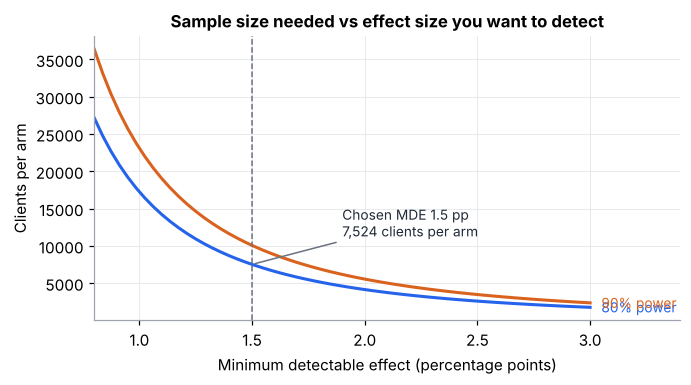

,MDE (pp),power,n per arm
0,1.0,0.8,17254
1,1.0,0.9,23099
2,1.5,0.8,7524
3,1.5,0.9,10073
4,2.0,0.8,4150
5,2.0,0.9,5555
6,2.5,0.8,2602
7,2.5,0.9,3483


In [6]:
sens = []
for mde in [0.010, 0.015, 0.020, 0.025]:
    for pw in [0.80, 0.90]:
        n = NormalIndPower().solve_power(proportion_effectsize(p0, p0 - mde), alpha=ALPHA, power=pw, ratio=1)
        sens.append({"MDE (pp)": mde * 100, "power": pw, "n per arm": int(np.ceil(n / (1 - EXCL)))})
sens = pd.DataFrame(sens)
R["design"]["sensitivity"] = sens.to_dict("records")

fig, ax = plt.subplots(figsize=(6.4, 3.6))
xs = np.linspace(0.008, 0.03, 60)
for pw, c, ls in [(0.8, BLUE, "-"), (0.9, ORANGE, "-")]:
    ys = [NormalIndPower().solve_power(proportion_effectsize(p0, p0 - m), alpha=ALPHA, power=pw) / (1 - EXCL) for m in xs]
    ax.plot(xs * 100, ys, color=c, lw=2, ls=ls)
    ax.text(xs[-1] * 100 + 0.05, ys[-1], f"{int(pw*100)}% power", color=c, va="center", fontsize=9)
ax.axvline(MDE * 100, color=GREY, ls="--", lw=1)
ax.annotate(f"Chosen MDE 1.5 pp\n{n_arm_adj:,} clients per arm", xy=(MDE * 100, n_arm_adj), xytext=(1.9, n_arm_adj * 1.5),
            arrowprops=dict(arrowstyle="-", color=GREY), fontsize=9, color=INK)
ax.set_xlabel("Minimum detectable effect (percentage points)"); ax.set_ylabel("Clients per arm")
ax.set_title("Sample size needed vs effect size you want to detect")
ax.set_xlim(0.8, 3.4)
plt.tight_layout(); plt.savefig(FIG / "fig_power.png"); plt.show()
sens

**Guardrail metrics** (things that must not get worse while we chase the primary metric)

| Metric | Why | Fail if |
|---|---|---|
| Opt-out of messages | WhatsApp can feel spammy | upper 95% bound of increase is above +1.0 pp |
| Revenue per completed visit | We should not be trading ticket size for show-ups | lower bound of change is below -3% |
| 60-day retention | Better show-up must not hurt return visits | lower bound of change is below -2 pp |
| Cancellations with notice | Reschedule link must not just move no-shows into cancellations | upper bound of increase is above +2 pp |

**Decision rule (written before looking at data).** GO if the primary CI is entirely below zero and no guardrail fails. NO-GO if the point estimate is not an improvement or any guardrail fails. EXTEND if the CI still includes zero but also the planned effect, i.e. the test is under-powered.

**Duration.** Enrol over the weeks computed above (a whole number of weeks, so every weekday is equally represented), measure no-show immediately after each index appointment, and wait a further 60 days for the retention guardrail.

## Part B. Analyse the experiment dataset

In [7]:
exp["T"] = (exp.arm == "treatment").astype(int)
n_c, n_t = int((exp["T"] == 0).sum()), int((exp["T"] == 1).sum())
N = n_c + n_t
chi, p_srm = stats.chisquare([n_c, n_t], [N / 2, N / 2])
# per outlet and per enrolment week
po = exp.groupby("outlet_id").T.agg(["sum", "count"]).assign(p=lambda d: [stats.binomtest(int(s), int(c), 0.5).pvalue for s, c in zip(d["sum"], d["count"])])
exp["enrol_week"] = (exp.enrol_date - exp.enrol_date.min()).dt.days // 7
pw_ = exp.groupby("enrol_week").T.agg(["sum", "count"]).assign(p=lambda d: [stats.binomtest(int(s), int(c), 0.5).pvalue for s, c in zip(d["sum"], d["count"])])
R["srm"] = {"n_control": n_c, "n_treatment": n_t, "share_treatment": n_t / N, "chi2": f(chi), "p": f(p_srm),
            "min_p_outlet": f(po.p.min()), "bonferroni_threshold_outlet": 0.05 / len(po),
            "min_p_week": f(pw_.p.min()), "outlet_flags": int((po.p < 0.05 / len(po)).sum())}
print(R["srm"])

{'n_control': 7044, 'n_treatment': 6956, 'share_treatment': 0.49685714285714283, 'chi2': 0.5531428571428572, 'p': 0.45703636040145645, 'min_p_outlet': 0.03318871913691822, 'bonferroni_threshold_outlet': 0.002272727272727273, 'min_p_week': 0.09451834113446089, 'outlet_flags': 0}


max |SMD| = 0.038; omnibus test of 'arm ~ all covariates' p = 0.119


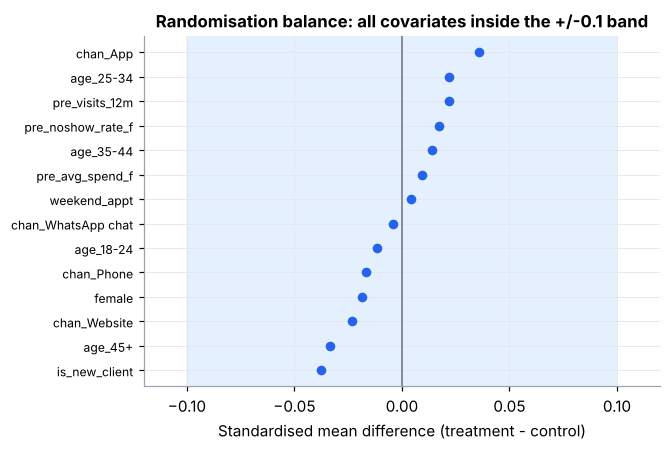

,covariate,control,treatment,SMD,p
0,is_new_client,0.2961,0.2790,-0.0378,0.0254
1,pre_visits_12m,2.2541,2.2954,0.0217,0.2000
2,pre_avg_spend_f,1074.6285,1078.2449,0.0093,0.5830
3,pre_noshow_rate_f,0.0665,0.0694,0.0172,0.3077
4,weekend_appt,0.2832,0.2851,0.0041,0.8075
5,female,0.7482,0.7401,-0.0185,0.2737
6,age_18-24,0.2250,0.2201,-0.0118,0.4844
7,age_25-34,0.3734,0.3840,0.0219,0.1954
8,age_35-44,0.2531,0.2592,0.0139,0.4102
9,age_45+,0.1485,0.1367,-0.0337,0.0463


In [8]:
# Randomisation balance: standardised mean differences on pre-experiment covariates
X = exp.copy()
X["pre_avg_spend_f"] = X.pre_avg_spend_inr.fillna(X.pre_avg_spend_inr.mean())
X["pre_noshow_rate_f"] = X.pre_noshow_rate.fillna(0)
for a in ["18-24", "25-34", "35-44", "45+"]: X[f"age_{a}"] = (X.age_group == a).astype(int)
for c in ["App", "Phone", "WhatsApp chat", "Website"]: X[f"chan_{c}"] = (X.booking_channel == c).astype(int)
X["female"] = (X.gender == "F").astype(int)
covs = ["is_new_client", "pre_visits_12m", "pre_avg_spend_f", "pre_noshow_rate_f", "weekend_appt", "female",
        "age_18-24", "age_25-34", "age_35-44", "age_45+", "chan_App", "chan_Phone", "chan_WhatsApp chat", "chan_Website"]
bal = []
for c in covs:
    a, b = X.loc[X["T"] == 1, c], X.loc[X["T"] == 0, c]
    smd = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    bal.append({"covariate": c, "control": b.mean(), "treatment": a.mean(), "SMD": smd, "p": stats.ttest_ind(a, b, equal_var=False).pvalue})
bal = pd.DataFrame(bal)
Xm = sm.add_constant(X[[c for c in covs if c not in ("age_45+", "chan_Website")]].astype(float))
lr = sm.Logit(X["T"], Xm).fit(disp=0)
lr0 = sm.Logit(X["T"], np.ones(len(X))).fit(disp=0)
lr_stat = 2 * (lr.llf - lr0.llf); lr_p = stats.chi2.sf(lr_stat, Xm.shape[1] - 1)
R["balance"] = {"max_abs_smd": f(bal.SMD.abs().max()), "omnibus_lr_p": f(lr_p), "min_p_covariate": f(bal.p.min()),
                "table": bal.round(4).to_dict("records")}
print(f"max |SMD| = {bal.SMD.abs().max():.3f}; omnibus test of 'arm ~ all covariates' p = {lr_p:.3f}")

fig, ax = plt.subplots(figsize=(6.2, 4.2))
bb = bal.sort_values("SMD")
ax.axvspan(-0.1, 0.1, color="#E5F0FF", zorder=0)
ax.scatter(bb.SMD, range(len(bb)), color=BLUE, s=28, zorder=3)
ax.set_yticks(range(len(bb))); ax.set_yticklabels(bb.covariate, fontsize=8)
ax.axvline(0, color=GREY, lw=1)
ax.set_xlabel("Standardised mean difference (treatment - control)"); ax.set_xlim(-0.12, 0.12)
ax.set_title("Randomisation balance: all covariates inside the +/-0.1 band")
plt.tight_layout(); plt.savefig(FIG / "fig_balance.png"); plt.show()
bal.round(4)

In [9]:
# Effects with confidence intervals
y1 = lambda col, d=exp: d.loc[d["T"] == 1, col].values
y0 = lambda col, d=exp: d.loc[d["T"] == 0, col].values

def prop_effect(col, d=exp, B=2000):
    a, b = y1(col, d).astype(float), y0(col, d).astype(float)
    diff = a.mean() - b.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    ci = (diff - 1.96 * se, diff + 1.96 * se)
    zst = diff / se; p = 2 * stats.norm.sf(abs(zst))
    boots = [rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(B)]
    bci = np.percentile(boots, [2.5, 97.5])
    rr = a.mean() / b.mean() if b.mean() > 0 else np.nan
    rr_se = np.sqrt((1 - a.mean()) / (len(a) * a.mean()) + (1 - b.mean()) / (len(b) * b.mean())) if a.mean() > 0 and b.mean() > 0 else np.nan
    return dict(control=f(b.mean()), treatment=f(a.mean()), diff=f(diff), se=f(se), lo=f(ci[0]), hi=f(ci[1]),
                boot_lo=f(bci[0]), boot_hi=f(bci[1]), p=f(p), rr=f(rr), rr_lo=f(rr * np.exp(-1.96 * rr_se)), rr_hi=f(rr * np.exp(1.96 * rr_se)))

def cont_effect(col, d=exp, B=2000):
    a, b = y1(col, d).astype(float), y0(col, d).astype(float)
    diff = a.mean() - b.mean()
    t = stats.ttest_ind(a, b, equal_var=False)
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    ci = (diff - 1.96 * se, diff + 1.96 * se)
    boots = [rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(B)]
    bci = np.percentile(boots, [2.5, 97.5])
    return dict(control=f(b.mean()), treatment=f(a.mean()), diff=f(diff), se=f(se), lo=f(ci[0]), hi=f(ci[1]),
                boot_lo=f(bci[0]), boot_hi=f(bci[1]), p=f(t.pvalue),
                pct=f(diff / b.mean()), pct_lo=f(ci[0] / b.mean()), pct_hi=f(ci[1] / b.mean()))

exp["cancelled_notice"] = (exp.status == "cancelled_with_notice").astype(int)
exp["rescheduled"] = (exp.status == "rescheduled").astype(int)
exp["retained"] = exp.retained_60d
AB = {
    "no_show": prop_effect("no_show"),
    "cancelled_notice": prop_effect("cancelled_notice"),
    "rescheduled": prop_effect("rescheduled"),
    "opted_out": prop_effect("opted_out"),
    "retained_60d": prop_effect("retained"),
    "rev_per_completed_visit": cont_effect("revenue_inr", exp[exp.completed == 1]),
    "rev_per_booked_appt": cont_effect("revenue_inr"),
}
R["ab"] = AB
tbl = pd.DataFrame({k: {"control": v["control"], "treatment": v["treatment"], "diff": v["diff"], "95% CI low": v["lo"], "95% CI high": v["hi"], "p": v["p"]} for k, v in AB.items()}).T
tbl.round(4)

,control,treatment,diff,95% CI low,95% CI high,p
no_show,0.1194,0.0930,-0.0264,-0.0366,-0.0162,0.0000
cancelled_notice,0.0578,0.0539,-0.0039,-0.0115,0.0037,0.3188
rescheduled,0.0098,0.0198,0.0100,0.0060,0.0140,0.0000
opted_out,0.0078,0.0102,0.0024,-0.0007,0.0055,0.1332
retained_60d,0.5371,0.5420,0.0049,-0.0116,0.0214,0.5588
rev_per_completed_visit,1095.6242,1092.1101,-3.5142,-24.7146,17.6862,0.7453
rev_per_booked_appt,890.7780,909.9871,19.2091,-3.0535,41.4717,0.0908


GO
 - Opt-out of messages (increase must stay below +1.0 pp) PASS
 - Revenue per completed visit (drop must stay above -3%) PASS
 - 60-day retention (drop must stay above -2 pp) PASS
 - Cancellations with notice (increase must stay below +2 pp) PASS


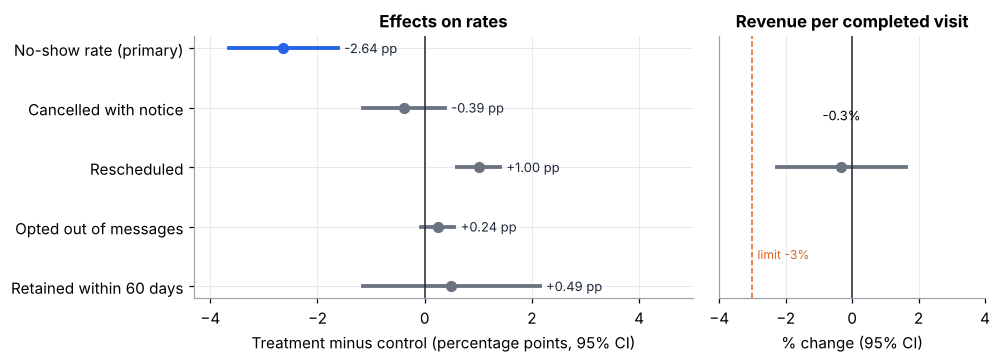

In [10]:
# Decision against the pre-registered rules
prim = AB["no_show"]
guards = {
    "Opt-out of messages (increase must stay below +1.0 pp)": AB["opted_out"]["hi"] < 0.010,
    "Revenue per completed visit (drop must stay above -3%)": AB["rev_per_completed_visit"]["pct_lo"] > -0.03,
    "60-day retention (drop must stay above -2 pp)": AB["retained_60d"]["lo"] > -0.02,
    "Cancellations with notice (increase must stay below +2 pp)": AB["cancelled_notice"]["hi"] < 0.020,
}
primary_ok = prim["hi"] < 0
if primary_ok and all(guards.values()):
    decision = "GO"
elif prim["diff"] >= 0 or not all(guards.values()):
    decision = "NO-GO"
else:
    decision = "EXTEND"
R["ab_decision"] = {"decision": decision, "primary_ci_below_zero": bool(primary_ok),
                    "guardrails": {k: bool(v) for k, v in guards.items()}}
print(decision); [print(" -", k, "PASS" if v else "FAIL") for k, v in guards.items()]

# forest plot (percentage points)
items = [("No-show rate (primary)", "no_show", BLUE), ("Cancelled with notice", "cancelled_notice", GREY),
         ("Rescheduled", "rescheduled", GREY), ("Opted out of messages", "opted_out", GREY), ("Retained within 60 days", "retained_60d", GREY)]
fig, axs = plt.subplots(1, 2, figsize=(9.2, 3.4), gridspec_kw={"width_ratios": [3, 1.6]})
ax = axs[0]
for i, (lab, k, c) in enumerate(items[::-1]):
    d = AB[k]
    ax.plot([d["lo"] * 100, d["hi"] * 100], [i, i], color=c, lw=2.5)
    ax.scatter(d["diff"] * 100, i, color=c, s=40, zorder=3)
    ax.text(d["hi"] * 100 + 0.12, i, f"{d['diff']*100:+.2f} pp", va="center", fontsize=8.5, color=INK)
ax.set_yticks(range(len(items))); ax.set_yticklabels([x[0] for x in items[::-1]])
ax.axvline(0, color=INK, lw=1); ax.set_xlabel("Treatment minus control (percentage points, 95% CI)")
ax.set_title("Effects on rates"); ax.set_xlim(-4.3, 5)
ax = axs[1]
d = AB["rev_per_completed_visit"]
ax.plot([d["pct_lo"] * 100, d["pct_hi"] * 100], [0, 0], color=GREY, lw=2.5); ax.scatter(d["pct"] * 100, 0, color=GREY, s=40, zorder=3)
ax.text(d["pct"] * 100, 0.18, f"{d['pct']*100:+.1f}%", ha="center", fontsize=8.5)
ax.axvline(0, color=INK, lw=1); ax.axvline(-3, color=ORANGE, ls="--", lw=1)
ax.text(-2.85, -0.35, "limit -3%", color=ORANGE, fontsize=8, ha="left")
ax.set_yticks([]); ax.set_ylim(-0.5, 0.5); ax.set_xlim(-4, 4); ax.set_title("Revenue per completed visit"); ax.set_xlabel("% change (95% CI)")
plt.tight_layout(); plt.savefig(FIG / "fig_ab_effects.png"); plt.show()

## Part C. Difference-in-differences for last quarter's change
**Setting.** The 14 Coimbatore outlets launched a change (loyalty points plus a premium add-on menu) on 1 July 2026. The 8 Tiruppur and Erode outlets did not. No experiment was run, so the control region tells us what would have happened anyway (seasonal festive demand, general trend).

**Estimator.** Two-way fixed effects on the outlet-week panel: `y = outlet effect + week effect + beta * (Coimbatore x post)`. The week effects soak up anything that hits both regions (seasonality). Standard errors are clustered by outlet. With only 22 clusters I use t-critical values with 21 degrees of freedom, and I also report a stratified cluster bootstrap and a permutation test.

In [11]:
# Outlet-week panel (drop partial weeks at the edges and the launch week)
drop_weeks = {pd.Timestamp("2024-12-30"), pd.Timestamp("2026-06-29"), pd.Timestamp("2026-09-28")}
ap = appt[~appt.week.isin(drop_weeks)]

def make_panel(d, extra=None):
    g = d.groupby(["outlet_id", "week"])
    p = g.agg(booked=("is_walkin", lambda s: (~s).sum()),
              noshow=("outcome", lambda s: (s == "no_show").sum()),
              completed=("outcome", lambda s: (s == "completed").sum()),
              revenue=("revenue", "sum")).reset_index()
    p = p[p.completed > 0]
    p["rpv"] = p.revenue / p.completed
    p["ns_rate"] = p.noshow / p.booked.replace(0, np.nan)
    p = p.merge(outlets[["outlet_id", "format", "change_launched"]], on="outlet_id")
    p["treated"] = (p.change_launched == "Y").astype(int)
    p["post"] = (p.week >= LAUNCH).astype(int)
    p["treat_post"] = p.treated * p.post
    p["week_s"] = p.week.dt.strftime("%Y%m%d")
    return p

panel = make_panel(ap)
print(panel.shape, "| outlets:", panel.outlet_id.nunique(), "| weeks:", panel.week.nunique(),
      "| pre weeks:", panel[panel.post == 0].week.nunique(), "| post weeks:", panel[panel.post == 1].week.nunique())

def twfe(p, ycol, coef="treat_post", log=False, formula_extra="", dropna=True):
    d = p.copy()
    d["y"] = np.log(d[ycol]) if log else d[ycol]
    d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=["y"])
    codes = d.outlet_id.astype("category").cat.codes
    m = smf.ols(f"y ~ {coef}{formula_extra} + C(outlet_id) + C(week_s)", data=d).fit(cov_type="cluster", cov_kwds={"groups": codes})
    G = codes.nunique()
    b, se = m.params[coef], m.bse[coef]
    tcrit = stats.t.ppf(0.975, G - 1)
    out = dict(b=f(b), se=f(se), lo=f(b - tcrit * se), hi=f(b + tcrit * se), p=f(2 * stats.t.sf(abs(b / se), G - 1)), G=int(G), n=int(len(d)))
    if log:
        out.update(pct=f(np.exp(b) - 1), pct_lo=f(np.exp(out["lo"]) - 1), pct_hi=f(np.exp(out["hi"]) - 1))
    return out, m

# naive before/after: what management claims (Coimbatore, Q3 vs Q2 2026) and what the control region did
def q_stats(d, a, b):
    s = d[(d.appt_date >= a) & (d.appt_date <= b)]
    cs = s[s.outcome == "completed"]
    return dict(rpv=f(cs.revenue.mean()), visits_per_outlet_week=f(len(cs) / s.outlet_id.nunique() / (((pd.Timestamp(b) - pd.Timestamp(a)).days + 1) / 7)))
naive = {}
for reg, flag in [("Coimbatore", True), ("Control", False)]:
    d = appt[appt.treated == flag]
    q2, q3 = q_stats(d, "2026-04-01", "2026-06-30"), q_stats(d, "2026-07-01", "2026-09-30")
    q2_25, q3_25 = q_stats(d, "2025-04-01", "2025-06-30"), q_stats(d, "2025-07-01", "2025-09-30")
    naive[reg] = {"rpv_q2": q2["rpv"], "rpv_q3": q3["rpv"], "rpv_change": q3["rpv"] / q2["rpv"] - 1,
                  "vis_change": q3["visits_per_outlet_week"] / q2["visits_per_outlet_week"] - 1,
                  "rpv_change_2025_same_quarters": q3_25["rpv"] / q2_25["rpv"] - 1}
R["naive"] = naive
pd.DataFrame(naive).T.round(4)

(1958, 14) | outlets: 22 | weeks: 89 | pre weeks: 77 | post weeks: 12


,rpv_q2,rpv_q3,rpv_change,vis_change,rpv_change_2025_same_quarters
Coimbatore,1198.5157,1221.3290,0.0190,0.0069,-0.0111
Control,1109.2259,1090.9577,-0.0165,-0.0068,0.0115


In [12]:
DID = {}
DID["rpv"], m_rpv = twfe(panel, "rpv", log=True)
DID["rpv_rupees"], _ = twfe(panel, "rpv")
DID["visits"], _ = twfe(panel, "completed", log=True)
DID["revenue"], _ = twfe(panel, "revenue", log=True)
DID["noshow"], _ = twfe(panel, "ns_rate")
R["did"] = DID

# Robustness 1: weighted by completed visits.  Robustness 2: stratified cluster bootstrap.  Robustness 3: permutation test.
d_ = panel.copy(); d_["y"] = np.log(d_.rpv)
codes = d_.outlet_id.astype("category").cat.codes
mw = smf.wls("y ~ treat_post + C(outlet_id) + C(week_s)", data=d_, weights=d_.completed).fit(cov_type="cluster", cov_kwds={"groups": codes})
w_b = mw.params["treat_post"]
DID["rpv_weighted_pct"] = f(np.exp(w_b) - 1)

o = d_.groupby(["outlet_id", "treated", "post"]).y.mean().unstack("post").reset_index()
o["delta"] = o[1] - o[0]
dt, dc = o[o.treated == 1].delta.values, o[o.treated == 0].delta.values
est = dt.mean() - dc.mean()
boot = [rng.choice(dt, len(dt)).mean() - rng.choice(dc, len(dc)).mean() for _ in range(5000)]
bci = np.percentile(boot, [2.5, 97.5])
allv = o.delta.values; perm = []
for _ in range(20000):
    idx = rng.permutation(len(allv)); perm.append(allv[idx[:len(dt)]].mean() - allv[idx[len(dt):]].mean())
perm_p = float(np.mean(np.abs(perm) >= abs(est)))
DID["rpv_collapsed"] = {"est_pct": f(np.exp(est) - 1), "boot_lo_pct": f(np.exp(bci[0]) - 1), "boot_hi_pct": f(np.exp(bci[1]) - 1), "perm_p": perm_p}
print("Revenue per visit, DiD:", {k: round(v, 4) if isinstance(v, float) else v for k, v in DID["rpv"].items()})
print("Weighted:", round(DID["rpv_weighted_pct"], 4), "| collapsed + bootstrap:", {k: round(v, 4) for k, v in DID["rpv_collapsed"].items()})

Revenue per visit, DiD: {'b': 0.0297, 'se': 0.0127, 'lo': 0.0033, 'hi': 0.0561, 'p': 0.0293, 'G': 22, 'n': 1958, 'pct': 0.0301, 'pct_lo': 0.0033, 'pct_hi': 0.0577}
Weighted: 0.0293 | collapsed + bootstrap: {'est_pct': 0.0301, 'boot_lo_pct': 0.006, 'boot_hi_pct': 0.0543, 'perm_p': 0.0248}


In [13]:
# Parallel-trends checks
pre = panel[panel.post == 0].copy()
pre["t10"] = (pre.week - pre.week.min()).dt.days / 70.0
pre["treat_x_t"] = pre.treated * pre.t10
slope, _ = twfe(pre, "rpv", coef="treat_x_t", log=True)

# placebo launch on 2026-01-05 using only pre-launch data
pre["pl_post"] = (pre.week >= pd.Timestamp("2026-01-05")).astype(int)
pre["placebo"] = pre.treated * pre.pl_post
placebo, _ = twfe(pre, "rpv", coef="placebo", log=True)

# event study by month (reference month = June 2026, the last full pre month)
es = panel.copy()
es["month"] = es.week.dt.to_period("M")
months = sorted(es.month.unique()); ref = pd.Period("2026-06")
terms = []
for mth in months:
    if mth == ref: continue
    nm = f"m_{mth.strftime('%Y_%m')}"
    es[nm] = ((es.month == mth) & (es.treated == 1)).astype(int); terms.append((nm, mth))
es["y"] = np.log(es.rpv)
codes_es = es.outlet_id.astype("category").cat.codes
m_es = smf.ols("y ~ " + " + ".join(t for t, _ in terms) + " + C(outlet_id) + C(week_s)", data=es).fit(cov_type="cluster", cov_kwds={"groups": codes_es})
tc = stats.t.ppf(0.975, 21)
# Re-centre on the AVERAGE of all pre-launch months (one noisy reference month would shift every bar):
# contrast for month m = coef_m - mean(pre-launch coefs, with the reference month counted as 0)
names = [t for t, _ in terms]
pre_names = [t for t, m in terms if m < pd.Period("2026-07")]
K_pre = len(pre_names) + 1                          # + the reference month
cov_es = m_es.cov_params().loc[names, names]
def contrast(target):
    c = pd.Series(0.0, index=names)
    if target is not None: c[target] = 1.0
    c[pre_names] -= 1.0 / K_pre
    return c
recs = []
for t, m in terms + [(None, ref)]:
    c = contrast(t)
    b = float(c @ m_es.params[names]); se = float(np.sqrt(c @ cov_es @ c))
    recs.append({"month": str(m), "b": b, "lo": b - tc * se, "hi": b + tc * se})
ev = pd.DataFrame(recs).sort_values("month").reset_index(drop=True)

# joint test: five pre-launch quarters (reference = 2026Q2) all equal zero
es["q"] = es.week.dt.to_period("Q")
qt = []
for q in sorted(es.q.unique()):
    if q == pd.Period("2026Q2") or q >= pd.Period("2026Q3"): continue
    nm = f"q_{str(q)}"; es[nm] = ((es.q == q) & (es.treated == 1)).astype(int); qt.append(nm)
es["post_t"] = es.treat_post
codes_q = es.outlet_id.astype("category").cat.codes
m_q = smf.ols("y ~ " + " + ".join(qt) + " + post_t + C(outlet_id) + C(week_s)", data=es).fit(cov_type="cluster", cov_kwds={"groups": codes_q})
wt = m_q.wald_test(", ".join(f"{n} = 0" for n in qt), use_f=True, scalar=True)
joint_p = f(wt.pvalue)
R["parallel"] = {"pretrend_slope_pct_per_10wk": slope["pct"], "pretrend_slope_lo": slope["pct_lo"], "pretrend_slope_hi": slope["pct_hi"],
                 "pretrend_slope_p": slope["p"], "placebo_pct": placebo["pct"], "placebo_lo": placebo["pct_lo"], "placebo_hi": placebo["pct_hi"],
                 "placebo_p": placebo["p"], "joint_lead_p": joint_p,
                 "event_pre_max_abs_pct": f(np.exp(ev[ev.month < "2026-07"].b.abs().max()) - 1),
                 "pre_months_total": int((ev.month < "2026-07").sum()),
                 "pre_months_ci_excl_zero": int(((ev.month < "2026-07") & ((ev.lo > 0) | (ev.hi < 0))).sum())}
print(json.dumps({k: round(v, 4) for k, v in R["parallel"].items()}, indent=1))

{
 "pretrend_slope_pct_per_10wk": -0.0003,
 "pretrend_slope_lo": -0.0055,
 "pretrend_slope_hi": 0.0048,
 "pretrend_slope_p": 0.8938,
 "placebo_pct": -0.001,
 "placebo_lo": -0.0178,
 "placebo_hi": 0.0162,
 "placebo_p": 0.9066,
 "joint_lead_p": 0.3385,
 "event_pre_max_abs_pct": 0.0376,
 "pre_months_total": 18,
 "pre_months_ci_excl_zero": 2
}


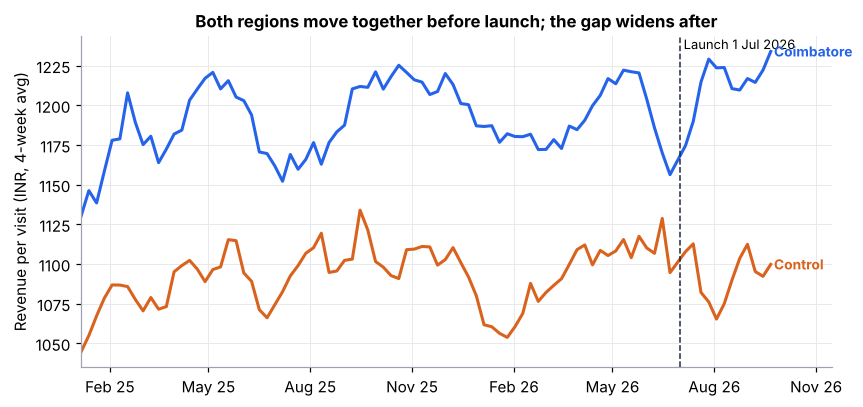

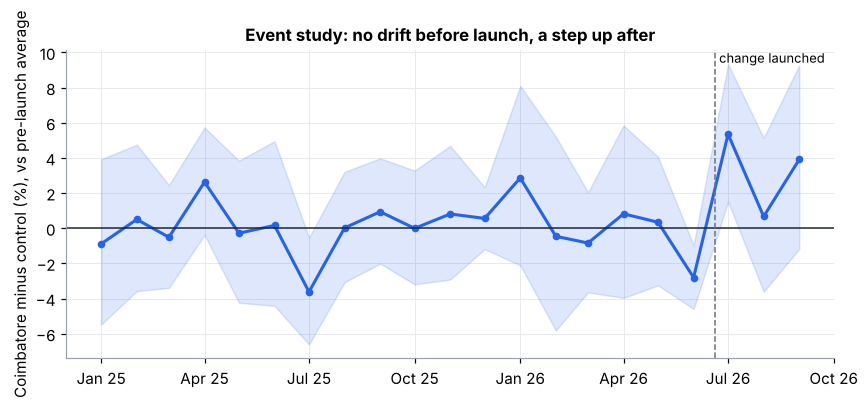

In [14]:
# Figure: trends, and event study
wk = ap.groupby(["treated", "week"]).apply(lambda d: d.revenue.sum() / (d.outcome == "completed").sum()).unstack(0).rename(columns={True: "Coimbatore (change)", False: "Tiruppur and Erode (no change)"})
sm4 = wk.rolling(4, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(sm4.index, sm4["Coimbatore (change)"], color=BLUE, lw=2); ax.plot(sm4.index, sm4["Tiruppur and Erode (no change)"], color=ORANGE, lw=2)
ax.axvline(LAUNCH, color=INK, ls="--", lw=1); ax.text(LAUNCH, ax.get_ylim()[1], " Launch 1 Jul 2026", va="top", fontsize=8.5)
ax.text(sm4.index[-1], sm4["Coimbatore (change)"].iloc[-1], " Coimbatore", color=BLUE, va="center", fontsize=9, fontweight="bold")
ax.text(sm4.index[-1], sm4["Tiruppur and Erode (no change)"].iloc[-1], " Control", color=ORANGE, va="center", fontsize=9, fontweight="bold")
ax.set_ylabel("Revenue per visit (INR, 4-week avg)"); ax.set_title("Both regions move together before launch; the gap widens after")
ax.set_xlim(sm4.index[0], sm4.index[-1] + pd.Timedelta(days=55))
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
plt.tight_layout(); plt.savefig(FIG / "fig_trends.png"); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.6))
x = pd.to_datetime(ev.month)
ax.fill_between(x, (np.exp(ev.lo) - 1) * 100, (np.exp(ev.hi) - 1) * 100, color=BLUE, alpha=0.15)
ax.plot(x, (np.exp(ev.b) - 1) * 100, color=BLUE, lw=2, marker="o", ms=4)
ax.axhline(0, color=INK, lw=1); ax.axvline(pd.Timestamp("2026-06-20"), color=GREY, ls="--", lw=1)
ax.text(pd.Timestamp("2026-06-20"), ax.get_ylim()[1], " change launched", va="top", fontsize=8.5)
ax.set_ylabel("Coimbatore minus control (%), vs pre-launch average"); ax.set_title("Event study: no drift before launch, a step up after")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
plt.tight_layout(); plt.savefig(FIG / "fig_event_study.png"); plt.show()
R["event_study"] = ev.round(5).to_dict("records")

## Part D. Segments: who gained and who lost?
The segment estimates are exploratory. I apply a Holm correction across all of them, and several segments have few outlets (flagged by the cluster count G).

In [15]:
SEG = []
def add_seg(family, label, p, ycol, log=True, note=""):
    try:
        r, _ = twfe(p, ycol, log=log)
    except Exception as e:
        return
    SEG.append(dict(family=family, segment=label, pct=r["pct"], lo=r["pct_lo"], hi=r["pct_hi"], p=r["p"], G=r["G"], n_treated_outlets=int(p[p.treated == 1].outlet_id.nunique())))

# client type
add_seg("Revenue per visit", "Booked clients", make_panel(ap[~ap.is_walkin]), "rpv")
add_seg("Revenue per visit", "Walk-ins", make_panel(ap[ap.is_walkin]), "rpv")
# service group
for g in ["Hair", "Skin & beauty", "Spa & bridal"]:
    add_seg("Revenue per visit", f"Service: {g}", make_panel(ap[ap.service_group == g]), "rpv")
# outlet format
for fm in ["Salon", "Salon & Spa", "Spa"]:
    ids = outlets[outlets.format == fm].outlet_id
    add_seg("Revenue per visit", f"Outlet format: {fm}", make_panel(ap[ap.outlet_id.isin(ids)]), "rpv")
# volume
add_seg("Visits", "Booked clients", make_panel(ap[~ap.is_walkin]), "completed")
add_seg("Visits", "Walk-ins", make_panel(ap[ap.is_walkin]), "completed")
seg = pd.DataFrame(SEG)
seg["p_holm"] = multipletests(seg.p, method="holm")[1]
R["did_segments"] = seg.round(5).to_dict("records")
seg.round(4)

,family,segment,pct,lo,hi,p,G,n_treated_outlets,p_holm
0,Revenue per visit,Booked clients,0.0460,0.0105,0.0828,0.0131,22,14,0.0917
1,Revenue per visit,Walk-ins,-0.0243,-0.0616,0.0145,0.2044,22,14,0.6131
2,Revenue per visit,Service: Hair,0.0425,0.0131,0.0727,0.0064,22,14,0.0514
3,Revenue per visit,Service: Skin & beauty,0.0420,0.0194,0.0652,0.0008,22,14,0.0083
4,Revenue per visit,Service: Spa & bridal,0.0414,-0.0714,0.1678,0.4702,22,14,0.8616
5,Revenue per visit,Outlet format: Salon,0.0153,-0.0266,0.0589,0.4308,9,6,0.8616
6,Revenue per visit,Outlet format: Salon & Spa,0.0312,-0.0079,0.0719,0.1039,9,6,0.4157
7,Revenue per visit,Outlet format: Spa,0.0428,-0.0038,0.0915,0.0616,4,2,0.3079
8,Visits,Booked clients,0.0367,0.0120,0.0620,0.0053,22,14,0.0477
9,Visits,Walk-ins,-0.0529,-0.1022,-0.0009,0.0465,22,14,0.2788


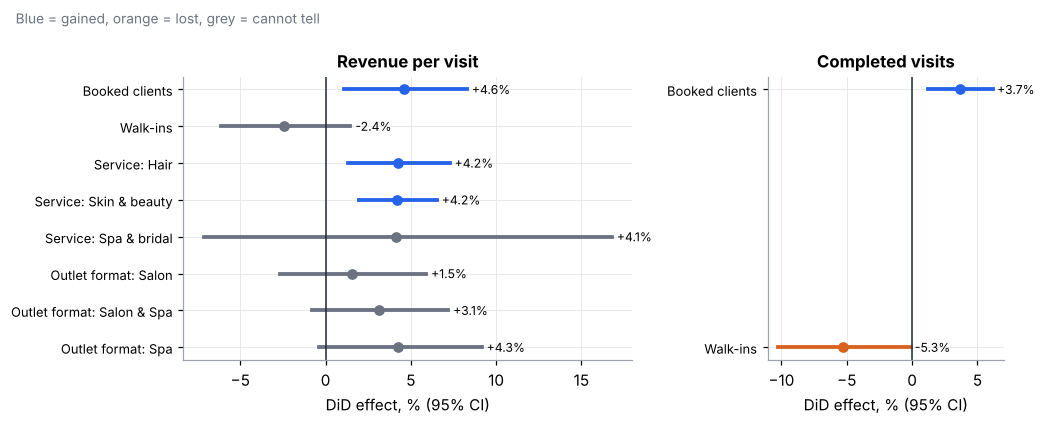

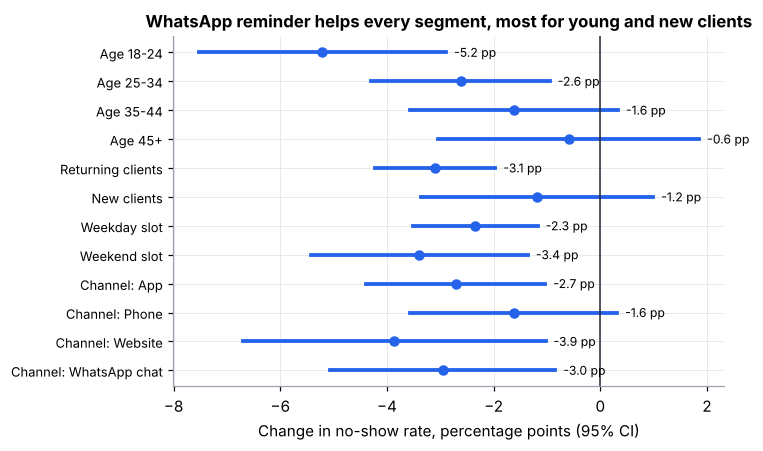

age x arm interaction (LR test) p = 0.1257


,segment,control,treatment,diff,lo,hi,p,n,p_holm
0,Age 18-24,0.1521,0.0999,-0.0521,-0.0753,-0.0289,0.0000,3116,0.0001
1,Age 25-34,0.1213,0.0951,-0.0262,-0.0429,-0.0095,0.0021,5301,0.0149
2,Age 35-44,0.1060,0.0899,-0.0162,-0.0356,0.0033,0.1038,3586,0.4033
3,Age 45+,0.0880,0.0820,-0.0059,-0.0304,0.0185,0.6347,1997,0.6347
4,Returning clients,0.1059,0.0750,-0.0309,-0.0422,-0.0197,0.0000,9973,0.0000
5,New clients,0.1515,0.1396,-0.0119,-0.0337,0.0099,0.2857,4027,0.5714
6,Weekday slot,0.1113,0.0879,-0.0234,-0.0351,-0.0117,0.0001,10022,0.0009
7,Weekend slot,0.1398,0.1059,-0.0339,-0.0543,-0.0136,0.0011,3978,0.0098
8,Channel: App,0.1223,0.0952,-0.0271,-0.0439,-0.0103,0.0016,5288,0.0126
9,Channel: Phone,0.1127,0.0965,-0.0162,-0.0356,0.0032,0.1008,3828,0.4033


In [16]:
fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.9), gridspec_kw={"width_ratios": [1.9, 1]})
for ax, fam, ttl in [(axs[0], "Revenue per visit", "Revenue per visit"), (axs[1], "Visits", "Completed visits")]:
    s = seg[seg.family == fam].iloc[::-1].reset_index(drop=True)
    for i, r in s.iterrows():
        c = BLUE if r.lo > 0 else (ORANGE if r.hi < 0 else GREY)
        ax.plot([r.lo * 100, r.hi * 100], [i, i], color=c, lw=2.5); ax.scatter(r.pct * 100, i, color=c, s=36, zorder=3)
        ax.text(r.hi * 100 + 0.3, i, f"{r.pct*100:+.1f}%", va="center", fontsize=8)
    ax.set_yticks(range(len(s))); ax.set_yticklabels(s.segment, fontsize=8.5); ax.axvline(0, color=INK, lw=1)
    ax.set_title(ttl); ax.set_xlabel("DiD effect, % (95% CI)")
plt.suptitle("Blue = gained, orange = lost, grey = cannot tell", fontsize=9, x=0.02, ha="left", color=GREY)
plt.tight_layout(); plt.savefig(FIG / "fig_did_segments.png"); plt.show()

# A/B segments: effect on no-show rate
SEGAB = []
def ab_seg(var, label_map=None):
    for lv, d in exp.groupby(var):
        a, b = d.loc[d["T"] == 1, "no_show"], d.loc[d["T"] == 0, "no_show"]
        diff = a.mean() - b.mean(); se = np.sqrt(a.var() / len(a) + b.var() / len(b))
        lab = f"{var}: {lv}" if not label_map else label_map[lv]
        SEGAB.append(dict(segment=lab, control=b.mean(), treatment=a.mean(), diff=diff, lo=diff - 1.96 * se, hi=diff + 1.96 * se,
                          p=2 * stats.norm.sf(abs(diff / se)), n=len(d)))
ab_seg("age_group", {k: f"Age {k}" for k in ["18-24", "25-34", "35-44", "45+"]})
ab_seg("is_new_client", {0: "Returning clients", 1: "New clients"})
ab_seg("weekend_appt", {0: "Weekday slot", 1: "Weekend slot"})
ab_seg("booking_channel", {k: f"Channel: {k}" for k in ["App", "Phone", "WhatsApp chat", "Website"]})
sab = pd.DataFrame(SEGAB); sab["p_holm"] = multipletests(sab.p, method="holm")[1]
# interaction test (arm x age) via likelihood ratio
m_int = smf.logit("no_show ~ T * C(age_group) + is_new_client", exp).fit(disp=0)
m_noi = smf.logit("no_show ~ T + C(age_group) + is_new_client", exp).fit(disp=0)
lr_int_p = f(stats.chi2.sf(2 * (m_int.llf - m_noi.llf), 3))
R["ab_segments"] = sab.round(5).to_dict("records"); R["ab_age_interaction_p"] = lr_int_p

fig, ax = plt.subplots(figsize=(7, 4.2))
s = sab.iloc[::-1].reset_index(drop=True)
for i, r in s.iterrows():
    ax.plot([r.lo * 100, r.hi * 100], [i, i], color=BLUE, lw=2.5); ax.scatter(r["diff"] * 100, i, color=BLUE, s=34, zorder=3)
    ax.text(r.hi * 100 + 0.15, i, f"{r['diff']*100:+.1f} pp", va="center", fontsize=8)
ax.set_yticks(range(len(s))); ax.set_yticklabels(s.segment, fontsize=8.5); ax.axvline(0, color=INK, lw=1)
ax.set_xlabel("Change in no-show rate, percentage points (95% CI)"); ax.set_title("WhatsApp reminder helps every segment, most for young and new clients")
plt.tight_layout(); plt.savefig(FIG / "fig_ab_segments.png"); plt.show()
print("age x arm interaction (LR test) p =", round(lr_int_p, 4))
sab.round(4)

## Part E (stretch). CUPED and regression adjustment
CUPED subtracts the part of the outcome that is predictable from pre-experiment behaviour: `Y_adj = Y - theta * (X - mean(X))`, with `theta = cov(Y, X) / var(X)`. The variance of the treatment effect shrinks by about `1 - rho^2`. Since sample size is proportional to variance, the test needs `(1 - rho^2)` of the weeks.

theta = 0.461, rho = 0.267, manual variance reduction = 7.1%


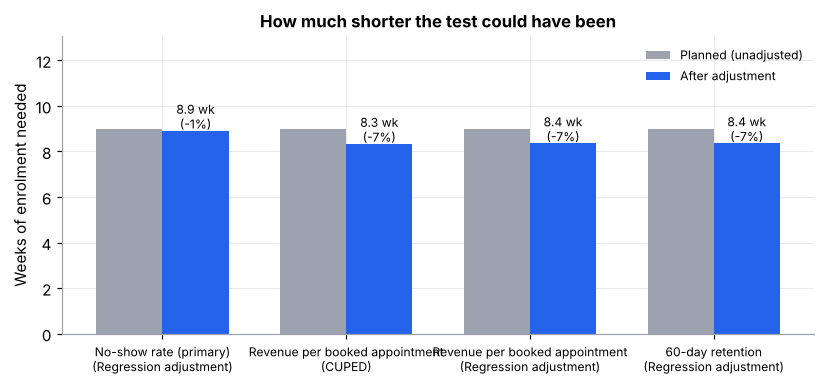

,metric,method,effect_raw,se_raw,effect_adj,se_adj,variance_reduction,weeks_needed,weeks_saved,ci_lo_adj,ci_hi_adj
0,No-show rate (primary),Regression adjustment,-0.0264,0.0052,-0.0258,0.0052,0.0101,8.9095,0.0905,-0.0359,-0.0156
1,Revenue per booked appointment,CUPED (pre-period spend),19.2091,11.3585,16.0681,10.9304,0.0740,8.3344,0.6656,-5.3556,37.4917
2,Revenue per booked appointment,Regression adjustment,19.2091,11.3585,15.6032,10.9448,0.0715,8.3564,0.6436,-5.8486,37.0551
3,60-day retention,Regression adjustment,0.0049,0.0084,0.0004,0.0081,0.0709,8.3621,0.6379,-0.0155,0.0163


In [17]:
Z = X.copy()
Z["no_show"] = Z.no_show; Z["rev"] = Z.revenue_inr
cov_terms = "pre_noshow_rate_f + pre_visits_12m + pre_avg_spend_f + is_new_client + C(age_group) + C(booking_channel) + weekend_appt + C(outlet_id)"

def adj(y, xterms):
    raw = smf.ols(f"{y} ~ T", Z).fit(cov_type="HC1")
    ad = smf.ols(f"{y} ~ T + {xterms}", Z).fit(cov_type="HC1")
    return raw, ad

rows = []
W = R["design"]["weeks"]
for label, y, xt, method in [("No-show rate (primary)", "no_show", cov_terms, "Regression adjustment"),
                             ("Revenue per booked appointment", "rev", "pre_avg_spend_f + is_new_client", "CUPED (pre-period spend)"),
                             ("Revenue per booked appointment", "rev", cov_terms, "Regression adjustment"),
                             ("60-day retention", "retained_60d", cov_terms, "Regression adjustment")]:
    raw, ad = adj(y, xt)
    ratio = (ad.bse["T"] / raw.bse["T"]) ** 2
    rows.append(dict(metric=label, method=method, effect_raw=raw.params["T"], se_raw=raw.bse["T"], effect_adj=ad.params["T"], se_adj=ad.bse["T"],
                     variance_reduction=1 - ratio, weeks_needed=W * ratio, weeks_saved=W * (1 - ratio),
                     ci_lo_adj=ad.params["T"] - 1.96 * ad.bse["T"], ci_hi_adj=ad.params["T"] + 1.96 * ad.bse["T"]))
cup = pd.DataFrame(rows)

# classic CUPED by hand for revenue (check against the regression)
xx = Z.pre_avg_spend_f; yy = Z.rev
theta = np.cov(yy, xx)[0, 1] / xx.var()
Z["rev_cuped"] = yy - theta * (xx - xx.mean())
a, b = Z.loc[Z["T"] == 1, "rev_cuped"], Z.loc[Z["T"] == 0, "rev_cuped"]
se_cuped = np.sqrt(a.var() / len(a) + b.var() / len(b))
a0, b0 = Z.loc[Z["T"] == 1, "rev"], Z.loc[Z["T"] == 0, "rev"]
se_raw_rev = np.sqrt(a0.var() / len(a0) + b0.var() / len(b0))
R["cuped"] = {"table": cup.round(5).to_dict("records"), "theta_revenue": f(theta), "rho_revenue": f(np.corrcoef(yy, xx)[0, 1]),
              "manual_var_reduction_revenue": f(1 - (se_cuped / se_raw_rev) ** 2), "planned_weeks": W}
print(f"theta = {theta:.3f}, rho = {np.corrcoef(yy, xx)[0,1]:.3f}, manual variance reduction = {1-(se_cuped/se_raw_rev)**2:.1%}")

fig, ax = plt.subplots(figsize=(7.6, 3.6))
lab = [f"{r.metric}\n({r.method.split(' (')[0]})" for r in cup.itertuples()]
xs = np.arange(len(cup)); wd = 0.36
ax.bar(xs - wd / 2, [W] * len(cup), wd, color="#9CA3AF", label="Planned (unadjusted)")
ax.bar(xs + wd / 2, cup.weeks_needed, wd, color=BLUE, label="After adjustment")
for i, r in enumerate(cup.itertuples()):
    ax.text(i + wd / 2, r.weeks_needed + 0.1, f"{r.weeks_needed:.1f} wk\n(-{r.variance_reduction*100:.0f}%)", ha="center", fontsize=8)
ax.set_xticks(xs); ax.set_xticklabels(lab, fontsize=8); ax.set_ylabel("Weeks of enrolment needed"); ax.legend(loc="upper right", fontsize=8)
ax.set_ylim(0, W * 1.45); ax.set_title("How much shorter the test could have been")
plt.tight_layout(); plt.savefig(FIG / "fig_cuped.png"); plt.show()
cup.round(4)

## Part F. Decision and what could make the estimates wrong

In [18]:
did_rpv = DID["rpv"]
did_dec = "GO (keep the change)" if did_rpv["pct_lo"] > 0 else ("NO-GO" if did_rpv["pct_hi"] < 0 else "EXTEND")
R["did_decision"] = did_dec
R["headline"] = {
    "ab_decision": R["ab_decision"]["decision"], "did_decision": did_dec,
    "claimed_rpv_change_pct": naive["Coimbatore"]["rpv_change"] * 100,
    "control_rpv_change_pct": naive["Control"]["rpv_change"] * 100,
    "did_rpv_pct": did_rpv["pct"] * 100, "did_rpv_lo": did_rpv["pct_lo"] * 100, "did_rpv_hi": did_rpv["pct_hi"] * 100,
}
print(json.dumps(R["headline"], indent=1))
json.dump(R, open(ROOT / "results.json", "w"), indent=1, default=float)

{
 "ab_decision": "GO",
 "did_decision": "GO (keep the change)",
 "claimed_rpv_change_pct": 1.9034616790823078,
 "control_rpv_change_pct": -1.6469346576935329,
 "did_rpv_pct": 3.0146335968576743,
 "did_rpv_lo": 0.33061096235598164,
 "did_rpv_hi": 5.770458619817043
}


### What could make the causal estimates wrong

**Difference-in-differences (last quarter's change)**
1. *Parallel trends fails after launch.* Coimbatore may have had its own post-July shock (a local festival, a competitor closing, a price change). The pre-period checks cannot rule this out; they only show the regions moved together before.
2. *Seasonality hits regions differently.* Festive demand might lift Coimbatore more than Tiruppur or Erode. The 2025 same-quarter comparison and the event-study leads are my protection.
3. *Spillovers.* Clients moving between regions, or shared advertising, would contaminate the control and bias the effect toward zero.
4. *Few clusters (22).* Standard errors can be too small; this is why I use t critical values, a bootstrap and a permutation test.
5. *Composition and measurement.* If the add-on menu changes which clients visit (more premium, fewer walk-ins), revenue per visit rises without any individual spending more. Visit volume and the segment results are the check.
6. *Outlets were not randomly picked.* Coimbatore outlets are larger and pricier; level differences are absorbed by outlet effects, but different trends are not.

**A/B test (WhatsApp reminder)**
1. *Sample ratio mismatch or broken randomisation* would invalidate everything; both checks passed here.
2. *Non-delivery.* Some clients will not receive or open WhatsApp; the estimate is intention-to-treat, so it understates the effect on those who do.
3. *Interference.* Family members booking together may see each other's reminders.
4. *Novelty effect.* Reminders may work best in the first weeks; we only observe eight.
5. *Revenue per completed visit conditions on showing up*, which the treatment changes, so it is a guardrail, not a causal ticket-size estimate.
6. *Multiple comparisons in segments.* Segment results are exploratory and Holm-adjusted.